# Tema 6, Exercițiul 1

### Notații

- $\theta$: rata de defectare (parametrul necunoscut, $0 < \theta < 1$);
- $n$: numărul de componente testate ($n = 50$);
- $Y$: numărul de componente defecte din cele $n$ testate;
- $y$: valoarea observată ($y = 8$);
- $\alpha, \beta$: parametrii priorului Beta ($\alpha = 2$, $\beta = 18$);
- $p(\theta)$: priorul, $p(y \mid \theta)$: verosimilitatea, $p(\theta \mid y)$: posteriorul.

## a) Modelul probabilistic

Fiecare componentă este defectă independent, cu probabilitatea $\theta$ (Bernoulli). Numărul de defecte din $n$ teste independente este binomial:

$$Y \mid \theta \sim \text{Bin}(n, \theta).$$

Funcția de verosimilitate (probabilitatea de a observa exact $y$ defecte) este

$$P(Y = y \mid \theta) = \binom{n}{y}\,\theta^{y}\,(1 - \theta)^{n - y}, \qquad y = 0, 1, \dots, n.$$

Ca funcție de $\theta$, factorul $\binom{n}{y}$ este o constantă, deci $p(y \mid \theta) \propto \theta^{y}(1 - \theta)^{n - y}$.

In [1]:
import numpy as np
from scipy.stats import beta, binom

n, y = 50, 8          # componente testate, defecte observate
alpha0, beta0 = 2, 18  # prior Beta(alpha, beta)

# verosimilitatea in punctul observat, pentru cateva valori ale lui theta
for th in [0.05, 0.10, 0.16, 0.30]:
    print(f"P(Y=8 | theta={th:.2f}) = {binom.pmf(y, n, th):.5f}")

P(Y=8 | theta=0.05) = 0.00243
P(Y=8 | theta=0.10) = 0.06428
P(Y=8 | theta=0.16) = 0.15225
P(Y=8 | theta=0.30) = 0.01099


## b) Actualizarea Bayesiană

Formula lui Bayes, fără constanta de normalizare:

$$p(\theta \mid y) \propto p(y \mid \theta)\,p(\theta).$$

Priorul Beta are densitatea $p(\theta) \propto \theta^{\alpha - 1}(1 - \theta)^{\beta - 1}$. Înmulțim cu verosimilitatea:

$$p(\theta \mid y) \propto \underbrace{\theta^{y}(1 - \theta)^{n - y}}_{\text{verosimilitate}}\;\underbrace{\theta^{\alpha - 1}(1 - \theta)^{\beta - 1}}_{\text{prior}} = \theta^{(\alpha + y) - 1}(1 - \theta)^{(\beta + n - y) - 1}.$$

Aceasta are forma unei densități Beta, deci priorul Beta este conjugat cu verosimilitatea binomială:

$$\theta \mid y \sim \text{Beta}\big(\alpha + y,\ \beta + n - y\big).$$

Înlocuind $\alpha = 2$, $\beta = 18$, $y = 8$, $n = 50$:

$$\theta \mid y \sim \text{Beta}(2 + 8,\ 18 + 50 - 8) = \text{Beta}(10,\ 60).$$

In [2]:
alpha_post = alpha0 + y            # alpha + y
beta_post = beta0 + n - y          # beta + (n - y)
print(f"posterior: Beta(alpha={alpha_post}, beta={beta_post})")

posterior: Beta(alpha=10, beta=60)


## c) Estimarea parametrului: MLE, MAP și media a posteriori

Folosim cele trei estimări definite în curs (slide-ul „MLE, MAP și media posteriorului"), aplicate posteriorului de la b), $\theta \mid y \sim \text{Beta}(a, b)$ cu $a = \alpha + y = 10$ și $b = \beta + n - y = 60$.

**MLE** — valoarea care maximizează verosimilitatea $p(y \mid \theta)$. Cursul dă direct, pentru modelul binomial,

$$\hat\theta_{\text{MLE}} = \frac{y}{n} = \frac{8}{50} = 0.16.$$

**MAP** — valoarea care maximizează posteriorul (modul distribuției). Cursul dă, pentru $\text{Beta}(a, b)$ cu $a, b > 1$,

$$\hat\theta_{\text{MAP}} = \frac{a - 1}{a + b - 2} = \frac{10 - 1}{10 + 60 - 2} = \frac{9}{68} \approx 0.132.$$

**Media a posteriori** — cursul o dă pe slide-ul „Interpretarea actualizării" sub forma actualizată $E[\theta \mid y] = \dfrac{\alpha + y}{\alpha + \beta + N}$, adică exact $\dfrac{a}{a + b}$ în parametrii posteriorului:

$$E[\theta \mid y] = \frac{a}{a + b} = \frac{10}{70} = \frac{1}{7} \approx 0.143.$$

In [3]:
mle = y / n
mapi = (alpha_post - 1) / (alpha_post + beta_post - 2)
mean_post = alpha_post / (alpha_post + beta_post)

print(f"MLE                = {mle:.4f}")
print(f"MAP                = {mapi:.4f}")
print(f"media a posteriori = {mean_post:.4f}")

MLE                = 0.1600
MAP                = 0.1324
media a posteriori = 0.1429


Cele trei valori: MLE $= 0.160$, MAP $\approx 0.132$, media $\approx 0.143$.

MLE folosește **doar datele** ($8/50$). MAP și media țin cont și de prior. Priorul $\text{Beta}(2, 18)$ are media $2/20 = 0.10$ și împinge estimările spre valori mai mici decât MLE. Media a posteriori este între prior ($0.10$) și MLE ($0.16$), fiind o medie ponderată a celor două. MAP este sub medie pentru că posteriorul $\text{Beta}(10, 60)$ este asimetric la dreapta (modul $<$ medie).

## d) Vizualizare: prior vs. posterior

Reprezentăm pe același grafic densitatea a priori $\text{Beta}(2, 18)$ și cea a posteriori $\text{Beta}(10, 60)$.

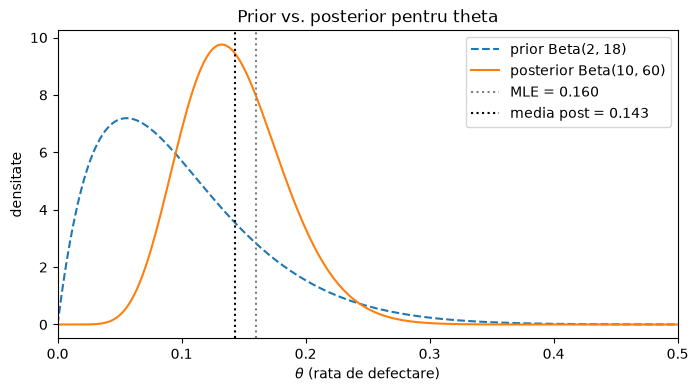

In [4]:
import matplotlib.pyplot as plt

grid = np.linspace(0, 1, 500)
prior_pdf = beta.pdf(grid, alpha0, beta0)
post_pdf = beta.pdf(grid, alpha_post, beta_post)

plt.figure(figsize=(8, 4))
plt.plot(grid, prior_pdf, "--", label=f"prior Beta({alpha0}, {beta0})")
plt.plot(grid, post_pdf, label=f"posterior Beta({alpha_post}, {beta_post})")
plt.axvline(mle, color="gray", ls=":", label=f"MLE = {mle:.3f}")
plt.axvline(mean_post, color="black", ls=":", label=f"media post = {mean_post:.3f}")
plt.xlabel(r"$\theta$ (rata de defectare)")
plt.ylabel("densitate")
plt.xlim(0, 0.5)
plt.legend()
plt.title("Prior vs. posterior pentru theta")
plt.show()

Datele (8 defecte din 50, deci o rată brută de $0.16$) au deplasat distribuția spre dreapta față de prior și au făcut-o mult mai **îngustă**: incertitudinea despre rata de defectare a scăzut considerabil după cele 50 de observații. Posteriorul concentrează masa de probabilitate în jurul valorii $\approx 0.14$.

## e) Incertitudine: interval credibil central de 95%

Un interval credibil central de 95% lasă câte $2.5\%$ din probabilitatea posterioară în fiecare coadă. Îl obținem din cuantilele posteriorului $\text{Beta}(10, 60)$ cu `scipy.stats.beta.ppf`.

In [5]:
lo, hi = beta.ppf([0.025, 0.975], alpha_post, beta_post)
print(f"interval credibil central 95%: [{lo:.4f}, {hi:.4f}]")

interval credibil central 95%: [0.0717, 0.2332]


Cu probabilitate posterioară de 95%, rata reală de defectare $\theta$ se află în intervalul $\approx [0.072,\ 0.233]$, condiționat de model și de date. Intervalul este relativ larg deoarece avem doar $y = 8$ defecte, dar exclude valori foarte mari ale ratei.

## f) Decizie practică: $P(\theta < 0.10 \mid Y = 8)$

Fabrica vrea o rată de defectare sub 10%. Aici regiunea de interes este $\{\theta < 0.10\}$, deci probabilitatea ei a posteriori este masa posteriorului de pe acel interval:

$$P(\theta < 0.10 \mid y) = \int_0^{0.10} p(\theta \mid y)\, d\theta.$$

O calculăm numeric cu funcția de repartiție a posteriorului $\text{Beta}(10, 60)$, prin `scipy.stats.beta.cdf`.

In [6]:
p_sub_10 = beta.cdf(0.10, alpha_post, beta_post)
print(f"P(theta < 0.10 | Y=8) = {p_sub_10:.4f}")

P(theta < 0.10 | Y=8) = 0.1484


$P(\theta < 0.10 \mid Y = 8) \approx 0.148$. Doar aproximativ $15\%$ din masa posterioară se află sub pragul de $10\%$, este mult mai probabil (85%) ca $\theta$ să depășească pragul. Observația se potrivește cu media a posteriori $\approx 0.143$, aflată peste prag.

## g) Predicție Bayesiană: $P(X = 0 \mid Y = 8)$ pentru 10 componente noi

Pentru un nou eșantion de $m = 10$ componente în aceleași condiții, numărul de defecte $X$ urmează $\text{Bin}(10, \theta)$ pentru $\theta$ dat. Integrăm peste incertitudinea a posteriori a lui $\theta$ (predicția posterioară):

$$P(X = 0 \mid Y = 8) = \int_0^1 (1 - \theta)^{10}\, p(\theta \mid Y = 8)\, d\theta.$$

Cu $p(\theta \mid y) = \dfrac{\theta^{\alpha_1 - 1}(1 - \theta)^{\beta_1 - 1}}{B(\alpha_1, \beta_1)}$ (unde $\alpha_1 = 10$, $\beta_1 = 60$), integrala recunoaște o funcție Beta:

$$P(X = 0 \mid Y = 8) = \frac{1}{B(\alpha_1, \beta_1)} \int_0^1 \theta^{\alpha_1 - 1}(1 - \theta)^{\beta_1 + 10 - 1}\, d\theta = \frac{B(\alpha_1,\ \beta_1 + 10)}{B(\alpha_1,\ \beta_1)}.$$

Verificăm rezultatul în două moduri: cu formula închisă (funcția Beta) și prin integrare numerică.

In [7]:
from scipy.special import betaln
from scipy.integrate import quad

m = 10  # componente noi

# forma inchisa: B(alpha1, beta1 + m) / B(alpha1, beta1)
pred_closed = np.exp(betaln(alpha_post, beta_post + m) - betaln(alpha_post, beta_post))

# verificare prin integrare numerica a definitiei
integrand = lambda th: (1 - th) ** m * beta.pdf(th, alpha_post, beta_post)
pred_num, _ = quad(integrand, 0, 1)

print(f"P(X=0 | Y=8), forma inchisa = {pred_closed:.4f}")
print(f"P(X=0 | Y=8), integrare num. = {pred_num:.4f}")

P(X=0 | Y=8), forma inchisa = 0.2360
P(X=0 | Y=8), integrare num. = 0.2360


Probabilitatea predictivă ca niciuna dintre cele 10 componente noi să nu fie defectă este $\approx 0.236$. Cele două metode (formula închisă cu funcția Beta și integrarea numerică) coincid, confirmând calculul. Predicția integrează incertitudinea despre $\theta$, nu folosește o singură valoare punctuală.